# Two-feature estimator and 3-simplex visualization

This notebook demonstrates 1. two-feature estimator for feature separability and trajectory estimation, 2. 3-simplex visualization. Run it from the repository root.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from theory.estimate import Estimate
from scripts import visualize_simplex


## Estimate feature separability from two performance observations

Each observation consists of an adjusted accuracy and its allocation `[alpha1, alpha0, beta]`. These are only illustrative values.

In [20]:
params0 = [0.12, 0.22, 0.96]
params1 = [0.50, 0.50, 0.50]
acc0 = 0.78
acc1 = 0.95

estimator = Estimate()
m1, m2, _ = estimator.solve_ms(acc0, acc1, params0, params1)
print(f'Estimated m1={m1:.4f}, m2={m2:.4f}')

Estimated m1=2.6839, m2=2.2982


## Estimate and plot every allocation trajectory

The methods are gradient, sign, balance, and random.

In [21]:
estimator = Estimate(m1=m1, m2=m2)
initial_params = [0.976, 0.184, 0.128]
num_steps = 25
delta_p = 0.01

trajectories = {}
trajectories['Grad'] = estimator.estimate_trajectory(
    initial_params, delta_p=delta_p, num_steps=num_steps
)
for name, method in [('Sign', 'sign'), ('Bal', 'bal')]:
    trajectories[name] = estimator.baseline_trajectory(
        initial_params, delta_p=delta_p, traj_type=method, num_steps=num_steps
    )
np.random.seed(0)
trajectories['Random'] = estimator.baseline_trajectory(
    initial_params, delta_p=delta_p, traj_type='random', num_steps=num_steps
)

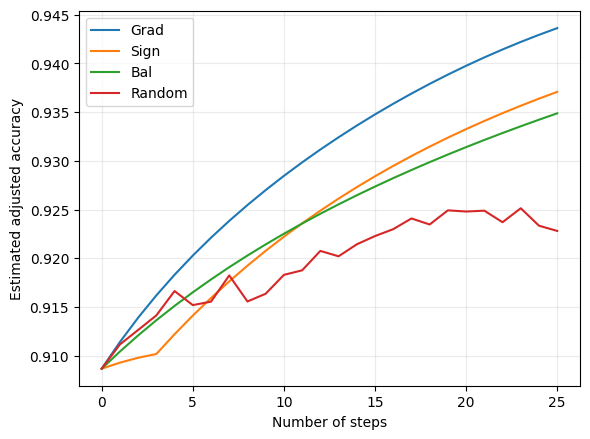

In [22]:
plt.figure(figsize=(6, 4.5))
for name, (acc_traj, _) in trajectories.items():
    steps = np.arange(len(acc_traj))
    plt.plot(steps, acc_traj.mean(axis=1), label=name)
plt.xlabel('Number of steps')
plt.ylabel('Estimated adjusted accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Visualize the Grad and Bal directions

The first update from the estimated trajectories defines each direction at `initial_params`. Grad and Bal are shown on separate 3-simplexes.

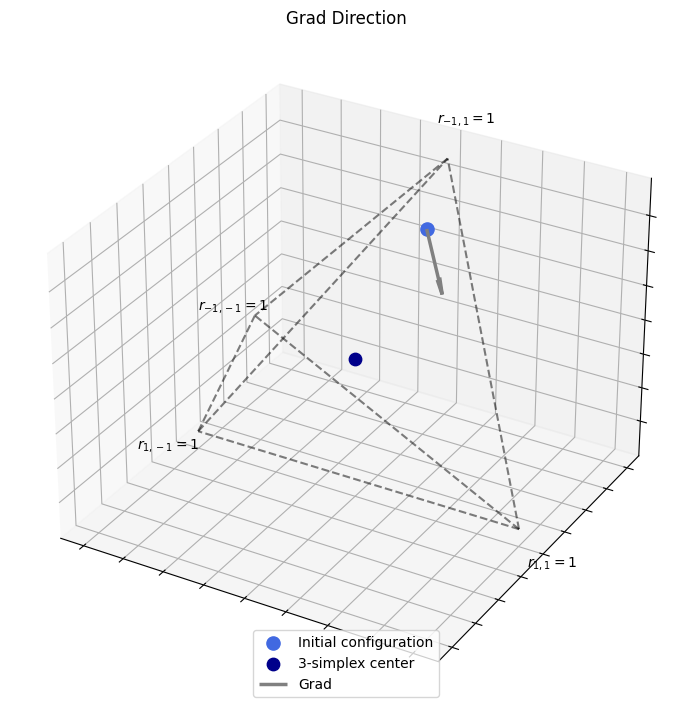

In [23]:
grad_params = trajectories['Grad'][1]
grad_direction = grad_params[1] - grad_params[0]

fig, ax = visualize_simplex.plot_direction(
    initial_params,
    grad_direction,
    step_size=delta_p,
    label='Grad',
    color='gray',
)
ax.set_title('Grad Direction')
plt.show()

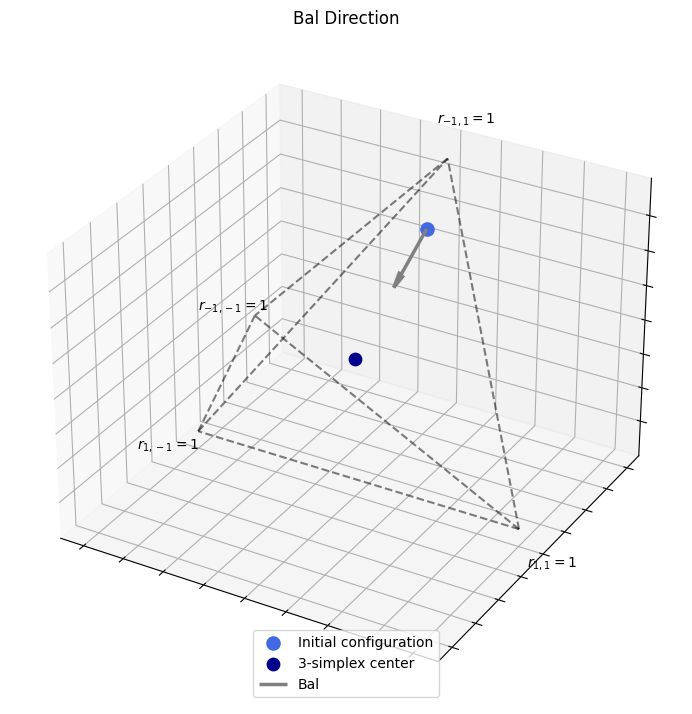

In [24]:
bal_params = trajectories['Bal'][1]
bal_direction = bal_params[1] - bal_params[0]

fig, ax = visualize_simplex.plot_direction(
    initial_params,
    bal_direction,
    step_size=delta_p,
    label='Bal',
    color='gray',
)
ax.set_title('Bal Direction')
plt.show()

## Theoretical simplex figures

The reference result `theory/reference/grid49_m1_2_m2_2.npz` uses the dense $49^3$ configuration grid for theoretical estimation.

In [15]:
with np.load('theory/reference/grid49_m1_2_m2_2.npz') as reference:
    dense_ratios = reference['ratios']
    dense_adjusted_acc = reference['acc'].mean(axis=1)
    dense_direction_similarity = reference['all_sim']
    dense_accuracy_gap = reference['all_acc_sim'].mean(axis=1)

### High-performance configurations

Configurations above the 90th-percentile theoretical adjusted accuracy are highlighted uniformly in yellow.

90th-percentile accuracy: 0.9178; displayed configurations: 11763


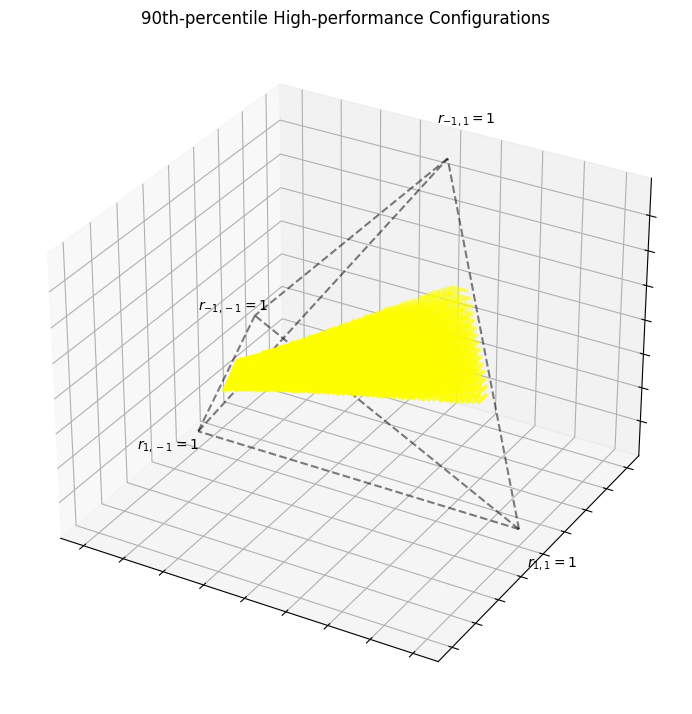

In [16]:
threshold = np.percentile(dense_adjusted_acc, 90)
high_performance = dense_adjusted_acc > threshold
print(
    f'90th-percentile accuracy: {threshold:.4f}; '
    f'displayed configurations: {high_performance.sum()}'
)

fig, ax = visualize_simplex.plot_performance(
    dense_ratios,
    dense_adjusted_acc,
    title='90th-percentile High-performance Configurations',
    label='Adjusted accuracy',
    mask=high_performance,
    marker_size=4,
    highlight=True,
)
plt.show()

### Grad–Bal direction similarity

The color of each configuration is the cosine similarity between the theoretical Grad and Bal directions. The color scale is fixed from 0 to 1 as in the paper.

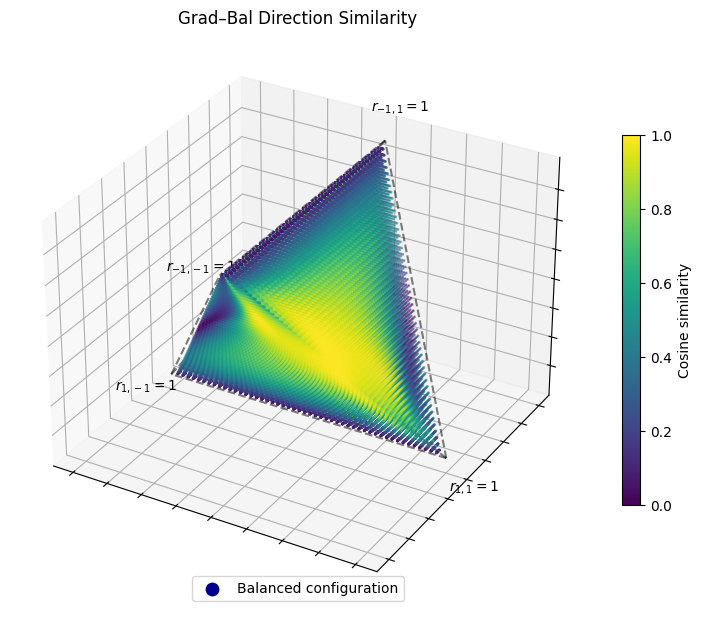

In [17]:
fig, ax = visualize_simplex.plot_performance(
    dense_ratios,
    dense_direction_similarity,
    title='Grad–Bal Direction Similarity',
    label='Cosine similarity',
    marker_size=1,
    colorbar_limits=(0, 1),
    show_balanced=True,
)
plt.show()

### Grad–Bal accuracy gap

The gap is the adjusted accuracy after 10 Grad steps minus that after 10 Bal steps. Following the paper plotting code, the mean group-accuracy gap is min–max normalized to $[0, 1]$ for visualization.

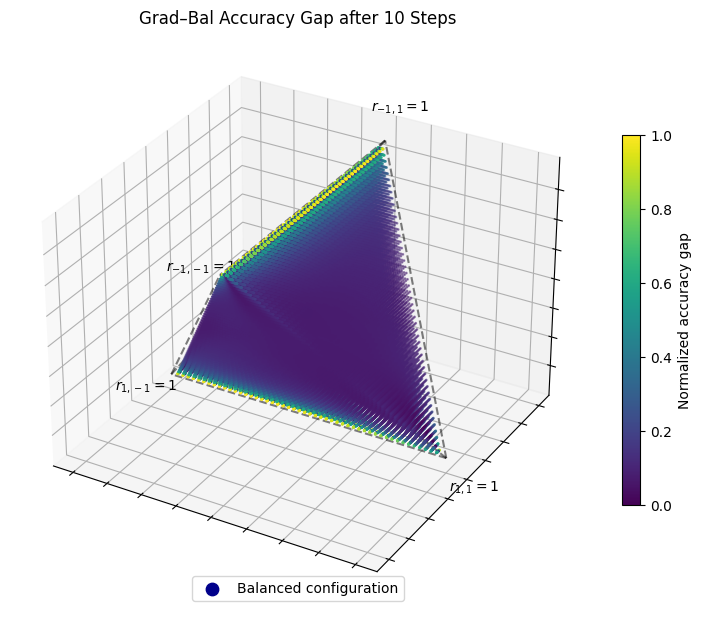

In [ ]:
normalized_accuracy_gap = (
    (dense_accuracy_gap - dense_accuracy_gap.min())
    / (dense_accuracy_gap.max() - dense_accuracy_gap.min())
)

fig, ax = visualize_simplex.plot_performance(
    dense_ratios,
    normalized_accuracy_gap,
    title='Grad–Bal Accuracy Gap after 10 Steps',
    label='Normalized accuracy gap',
    marker_size=1,
    colorbar_limits=(0, 1),
    show_balanced=True,
)
plt.show()